In [2]:
import pandas as pd
import numpy as np
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("Pandas version:", pd.__version__)

TensorFlow version: 2.21.0
Pandas version: 2.3.3


In [3]:
df = pd.read_csv("Train.csv")

In [4]:
X = df.drop("readmitted", axis=1)

y = df["readmitted"]

In [5]:
categorical_cols = X.select_dtypes(include=["object"]).columns

print(categorical_cols)

Index(['race', 'gender', 'age', 'weight', 'medical_specialty', 'diag_1',
       'diag_2', 'diag_3', 'diag_4', 'X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7',
       'X8', 'X9', 'X10', 'X11', 'X12', 'X13', 'X14', 'X15', 'X16', 'X17',
       'X18', 'X19', 'X20', 'X21', 'X22', 'X23', 'X24', 'X25', 'change',
       'diabetesMed'],
      dtype='object')


In [6]:
X_encoded = pd.get_dummies(X, columns=categorical_cols)

print("Original shape:", X.shape)
print("Encoded shape:", X_encoded.shape)

Original shape: (66587, 48)
Encoded shape: (66587, 2904)


In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (53269, 2904)
Testing data: (13318, 2904)


In [8]:
import matplotlib.pyplot as plt

In [52]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaling completed!")
print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Scaling completed!
Scaled training shape: (53269, 2904)
Scaled testing shape: (13318, 2904)


In [53]:
import pickle

with open("scaler.pkl", "wb") as f:
    pickle.dump(scaler, f)

print("Scaler saved successfully!")

Scaler saved successfully!


In [54]:
feature_columns = X_encoded.columns.tolist()

with open("feature_columns.pkl", "wb") as f:
    pickle.dump(feature_columns, f)

print("Feature columns saved successfully!")
print("Number of features:", len(feature_columns))

Feature columns saved successfully!
Number of features: 2904


In [55]:
test_loss, test_accuracy = model.evaluate(
    X_test_scaled,
    y_test,
    verbose=1
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Test Accuracy (%):", round(test_accuracy * 100, 2))

417/417 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6711 - loss: 0.6679
Test Loss: 0.6678606867790222
Test Accuracy: 0.6711217761039734
Test Accuracy (%): 67.11


In [56]:
y_pred_prob = model.predict(X_test_scaled)

y_pred = (y_pred_prob >= 0.5).astype(int).ravel()

print("Predictions generated successfully!")
print("Number of predictions:", len(y_pred))

417/417 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
Predictions generated successfully!
Number of predictions: 13318


In [57]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.68      0.72      0.70      7165
           1       0.65      0.61      0.63      6153

    accuracy                           0.67     13318
   macro avg       0.67      0.67      0.67     13318
weighted avg       0.67      0.67      0.67     13318



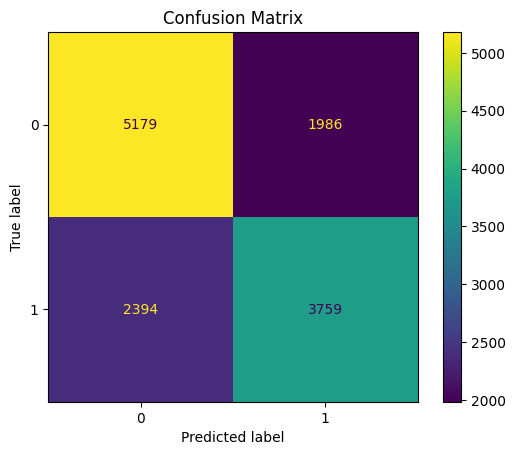

In [58]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()

plt.title("Confusion Matrix")
plt.show()

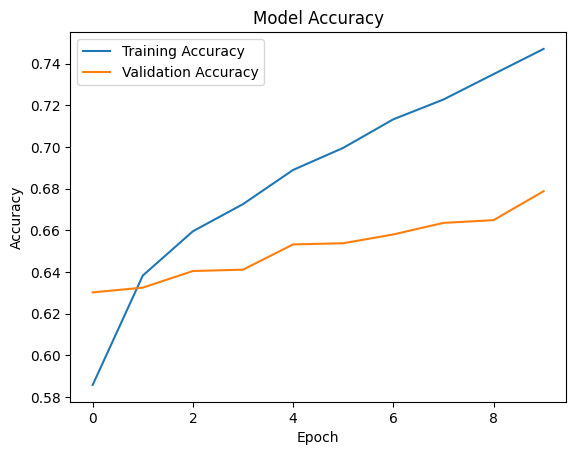

In [60]:
plt.plot(history.history["accuracy"])
plt.plot(history.history["val_accuracy"])

plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend(["Training Accuracy", "Validation Accuracy"])

plt.show()

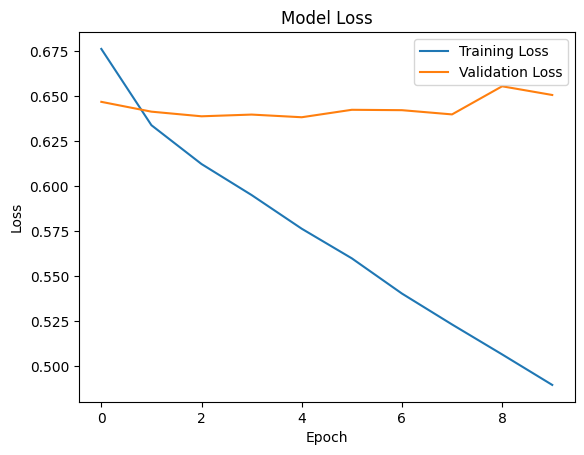

In [61]:
plt.plot(history.history["loss"])
plt.plot(history.history["val_loss"])

plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend(["Training Loss", "Validation Loss"])

plt.show()

In [62]:
model.save("hospital_readmission_model.keras")

print("Model saved successfully!")

Model saved successfully!


In [63]:
test_loss, test_accuracy = model.evaluate(
    X_test_scaled,
    y_test,
    verbose=1
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Test Accuracy (%):", round(test_accuracy * 100, 2))

417/417 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6711 - loss: 0.6679
Test Loss: 0.6678606867790222
Test Accuracy: 0.6711217761039734
Test Accuracy (%): 67.11


In [10]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

model = Sequential()

# Input + First Hidden Layer
model.add(Dense(128, activation="relu", input_shape=(X_train_scaled.shape[1],)))
model.add(Dropout(0.3))

# Second Hidden Layer
model.add(Dense(64, activation="relu"))
model.add(Dropout(0.2))

# Third Hidden Layer
model.add(Dense(32, activation="relu"))

# Output Layer
model.add(Dense(1, activation="sigmoid"))

print("Neural Network model created successfully!")

Neural Network model created successfully!


C:\Users\ASUS\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [11]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [12]:
history = model.fit(
    X_train_scaled,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/10
1332/1332 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.5859 - loss: 0.6761 - val_accuracy: 0.6303 - val_loss: 0.6467
Epoch 2/10
1332/1332 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6383 - loss: 0.6338 - val_accuracy: 0.6325 - val_loss: 0.6413
Epoch 3/10
1332/1332 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6596 - loss: 0.6122 - val_accuracy: 0.6405 - val_loss: 0.6387
Epoch 4/10
1332/1332 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6726 - loss: 0.5950 - val_accuracy: 0.6412 - val_loss: 0.6396
Epoch 5/10
1332/1332 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6890 - loss: 0.5763 - val_accuracy: 0.6533 - val_loss: 0.6382
Epoch 6/10
1332/1332 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6996 - loss: 0.5599 - val_accuracy: 0.6538 - val_loss: 0.6423
Epoch 7/10
1332/1332 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7133 - loss: 0.5404 - val_accuracy: 0.6581 - val_loss: 0.6421
Epoch 8/10
1332/1332 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7228 - loss: 0.5232 - 

In [13]:
test_loss, test_accuracy = model.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

Test Loss: 0.6678606867790222
Test Accuracy: 0.6711217761039734


In [14]:
y_pred_prob = model.predict(X_test_scaled)

print(y_pred_prob[:10])

417/417 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
[[0.02435977]
 [0.7199553 ]
 [0.0145108 ]
 [0.7619423 ]
 [0.5785701 ]
 [0.21466494]
 [0.5043787 ]
 [0.54858005]
 [0.91434264]
 [0.38807353]]


In [15]:
y_pred = (y_pred_prob > 0.5).astype(int)

print(y_pred[:10])

[[0]
 [1]
 [0]
 [1]
 [1]
 [0]
 [1]
 [1]
 [1]
 [0]]


In [16]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Final Test Accuracy:", accuracy)
print("Final Test Accuracy Percentage:", accuracy * 100)

Final Test Accuracy: 0.6711217900585673
Final Test Accuracy Percentage: 67.11217900585673


In [17]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.68      0.72      0.70      7165
           1       0.65      0.61      0.63      6153

    accuracy                           0.67     13318
   macro avg       0.67      0.67      0.67     13318
weighted avg       0.67      0.67      0.67     13318



In [18]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[5179 1986]
 [2394 3759]]


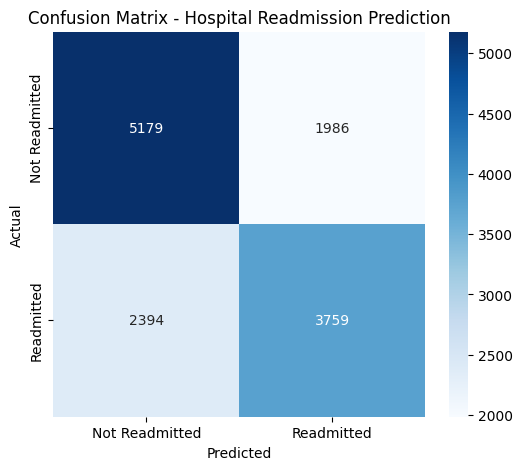

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Readmitted", "Readmitted"],
    yticklabels=["Not Readmitted", "Readmitted"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Hospital Readmission Prediction")

plt.show()

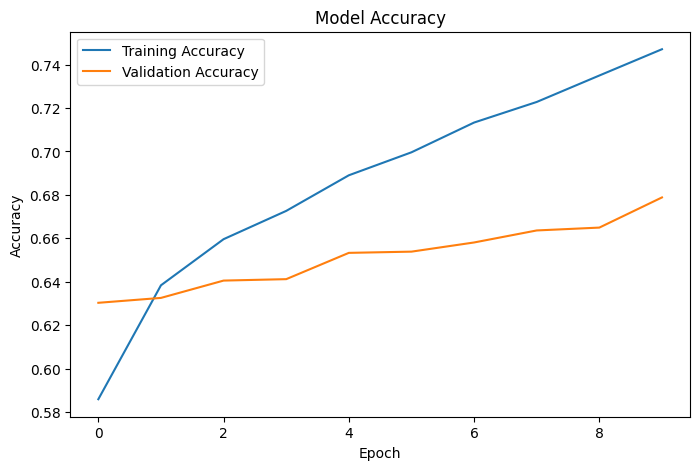

In [20]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.show()

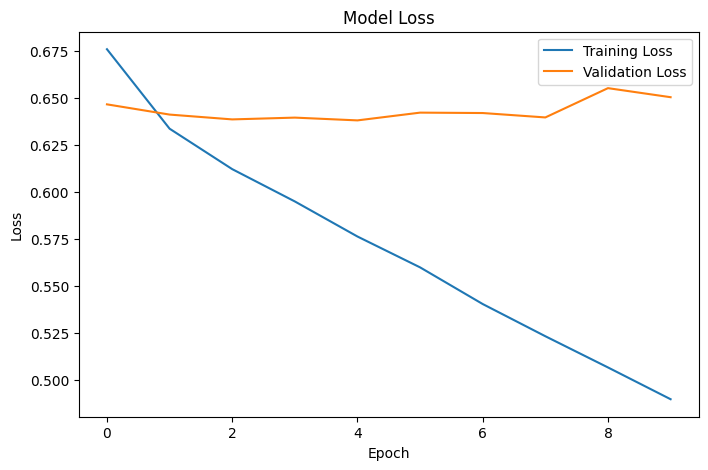

In [21]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.show()

In [22]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       371,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,146,629 (4.37 MB)

 Trainable params: 382,209 (1.46 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 764,420 (2.92 MB)

In [23]:
model.save("hospital_readmission_neural_network.keras")

print("Model saved successfully!")

Model saved successfully!


In [24]:
import joblib

joblib.dump(scaler, "scaler.pkl")

print("Scaler saved successfully!")

Scaler saved successfully!


In [25]:
print("=" * 50)
print("HOSPITAL READMISSION PREDICTION PROJECT")
print("=" * 50)

print("Dataset Shape:", df.shape)
print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

print("\nTest Accuracy:", round(test_accuracy * 100, 2), "%")

print("=" * 50)

HOSPITAL READMISSION PREDICTION PROJECT
Dataset Shape: (66587, 49)
Training Samples: 53269
Testing Samples: 13318

Test Accuracy: 67.11 %


In [26]:
y_pred = y_pred.flatten()

In [27]:
df = pd.read_csv("Train.csv")

In [28]:
X = df.drop("readmitted", axis=1)
y = df["readmitted"]

In [29]:
categorical_cols = X.select_dtypes(include="object").columns.tolist()

In [30]:
df = pd.read_csv("Train.csv")

print("Dataset loaded successfully!")
print(df.shape)

Dataset loaded successfully!
(66587, 49)


In [31]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 66587 entries, 0 to 66586
Data columns (total 49 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   index               66587 non-null  int64  
 1   encounter_id        66587 non-null  int64  
 2   patient_id          66587 non-null  int64  
 3   race                66587 non-null  object 
 4   gender              66587 non-null  object 
 5   age                 66587 non-null  object 
 6   weight              66587 non-null  object 
 7   time_in_hospital    66587 non-null  int64  
 8   medical_specialty   66587 non-null  object 
 9   num_lab_procedures  66587 non-null  int64  
 10  num_procedures      66587 non-null  int64  
 11  num_medications     66587 non-null  int64  
 12  number_outpatient   66587 non-null  int64  
 13  number_emergency    66587 non-null  int64  
 14  number_inpatient    66587 non-null  int64  
 15  diag_1              66587 non-null  object 
 16  diag

In [32]:
df.isnull().sum()

index                     0
encounter_id              0
patient_id                0
race                      0
gender                    0
age                       0
weight                    0
time_in_hospital          0
medical_specialty         0
num_lab_procedures        0
num_procedures            0
num_medications           0
number_outpatient         0
number_emergency          0
number_inpatient          0
diag_1                    0
diag_2                    0
diag_3                    0
diag_4                    0
diag_5                    0
number_diagnoses          0
X1                    63104
X2                    55451
X3                        0
X4                        0
X5                        0
X6                        0
X7                        0
X8                        0
X9                        0
X10                       0
X11                       0
X12                       0
X13                       0
X14                       0
X15                 

In [33]:
print(df.columns.tolist())

['index', 'encounter_id', 'patient_id', 'race', 'gender', 'age', 'weight', 'time_in_hospital', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'diag_4', 'diag_5', 'number_diagnoses', 'X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10', 'X11', 'X12', 'X13', 'X14', 'X15', 'X16', 'X17', 'X18', 'X19', 'X20', 'X21', 'X22', 'X23', 'X24', 'X25', 'change', 'diabetesMed', 'readmitted']


In [34]:
print(df["readmitted"].value_counts())

readmitted
0    35823
1    30764
Name: count, dtype: int64


In [35]:
X = df.drop("readmitted", axis=1)
y = df["readmitted"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (66587, 48)
y shape: (66587,)


In [36]:
X = df.drop("readmitted", axis=1)

In [37]:
y = df["readmitted"]

In [38]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (66587, 48)
y shape: (66587,)


In [39]:
print(X.dtypes)

index                   int64
encounter_id            int64
patient_id              int64
race                   object
gender                 object
age                    object
weight                 object
time_in_hospital        int64
medical_specialty      object
num_lab_procedures      int64
num_procedures          int64
num_medications         int64
number_outpatient       int64
number_emergency        int64
number_inpatient        int64
diag_1                 object
diag_2                 object
diag_3                 object
diag_4                 object
diag_5                float64
number_diagnoses        int64
X1                     object
X2                     object
X3                     object
X4                     object
X5                     object
X6                     object
X7                     object
X8                     object
X9                     object
X10                    object
X11                    object
X12                    object
X13       

In [40]:
categorical_cols = X.select_dtypes(include="object").columns.tolist()

print("Categorical/Text columns:")
print(categorical_cols)

print("\nNumber of categorical columns:", len(categorical_cols))

Categorical/Text columns:
['race', 'gender', 'age', 'weight', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'diag_4', 'X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10', 'X11', 'X12', 'X13', 'X14', 'X15', 'X16', 'X17', 'X18', 'X19', 'X20', 'X21', 'X22', 'X23', 'X24', 'X25', 'change', 'diabetesMed']

Number of categorical columns: 36


In [41]:
numerical_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()

print("Numerical columns:", numerical_cols)
print("Number of numerical columns:", len(numerical_cols))

Numerical columns: ['index', 'encounter_id', 'patient_id', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_5', 'number_diagnoses']
Number of numerical columns: 12


In [42]:
missing = X.isnull().sum()

print(missing[missing > 0])

X1    63104
X2    55451
dtype: int64


In [43]:
print("X1 unique values:")
print(X["X1"].value_counts(dropna=False).head(10))

print("\nX2 unique values:")
print(X["X2"].value_counts(dropna=False).head(10))

X1 unique values:
X1
NaN     63104
Norm     1643
>200      991
>300      849
Name: count, dtype: int64

X2 unique values:
X2
NaN     55451
>8       5342
Norm     3246
>7       2548
Name: count, dtype: int64


In [44]:

for col in categorical_cols:
    X[col] = X[col].fillna("Unknown")

print("Missing values in categorical columns handled!")

Missing values in categorical columns handled!


In [45]:
print(X[categorical_cols].isnull().sum().sum())

0


In [46]:
print(X[numerical_cols].isnull().sum())

index                 0
encounter_id          0
patient_id            0
time_in_hospital      0
num_lab_procedures    0
num_procedures        0
num_medications       0
number_outpatient     0
number_emergency      0
number_inpatient      0
diag_5                0
number_diagnoses      0
dtype: int64


In [47]:
print(df["readmitted"].value_counts())

readmitted
0    35823
1    30764
Name: count, dtype: int64


In [48]:
model.save("hospital_readmission_model.keras")

In [49]:
test_loss, test_accuracy = model.evaluate(
    X_test_scaled,
    y_test
)

417/417 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6711 - loss: 0.6679


In [50]:
model.save("hospital_readmission_model.keras")

In [51]:
import pickle

# Save the feature names used by the trained model
with open("feature_columns.pkl", "wb") as f:
    pickle.dump(X_encoded.columns.tolist(), f)

print("Feature columns saved successfully!")
print("Number of features:", len(X_encoded.columns))

Feature columns saved successfully!
Number of features: 2904
